Corrección de desfase 12h.
El objetivo es detectar qué variables están desfasadas y corregirlas



In [1]:
from pathlib import Path 
import pandas as pd 
import matplotlib.pyplot as plt 

ENTRADA_RUTA = Path("transformado/db_meteorologica_unificada.json")

df = pd.read_json(ENTRADA_RUTA)
df.head()

,station_id,timestamp,id,temperature_c,humidity_pct,wind_speed_kmh,wind_direction_deg,pressure_hpa,precipitation_mm,visibility_km,uv_index
0,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 00:00:00+00:00,ccdcf0e5-6ca1-4d82-bc25-0881de96dc7c,32.4,68.9,23.1,45.7,1013.2,0.0,11.8,0.0
1,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 00:05:00+00:00,7b432baa-8447-49bd-8745-f6bce07b2aa5,32.4,68.9,23.1,45.3,1013.2,0.0,12.1,0.0
2,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 00:10:00+00:00,df2d0bbd-8384-4467-8b77-aefd811a1a3f,32.6,68.7,23.0,44.8,1013.2,0.0,11.8,0.0
3,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 00:15:00+00:00,0d7a67f8-f725-426f-b905-220fb4d987fa,32.6,68.6,23.0,45.3,1013.2,0.0,11.8,0.0
4,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 00:20:00+00:00,939fdce1-c965-4452-b614-25144385ed55,32.8,68.6,22.8,45.1,1013.2,0.0,12.5,0.0


In [2]:
df.dtypes

station_id                            str
timestamp             datetime64[us, UTC]
id                                    str
temperature_c                     float64
humidity_pct                      float64
wind_speed_kmh                    float64
wind_direction_deg                float64
pressure_hpa                      float64
precipitation_mm                  float64
visibility_km                     float64
uv_index                          float64
dtype: object

In [3]:
df = df.sort_values(["station_id", "timestamp"]).reset_index(drop=True) #Reordenamos y asignamos índice 

In [4]:
print(df["timestamp"].min(), "→", df["timestamp"].max())
print("Estaciones:", df["station_id"].nunique())
print("Filas:", len(df))

2025-09-01 00:00:00+00:00 → 2026-09-17 21:55:00+00:00
Estaciones: 12
Filas: 1292256


In [5]:
#Vamos a comprobar la frecuencia entre lecturas
df.groupby("station_id")["timestamp"].diff().value_counts()

timestamp
0 days 00:05:00    1292220
7 days 00:05:00         12
1 days 00:05:00         12
Name: count, dtype: int64

Tenemos varios saltos en el tiempo de registros, habrá que eliminarlo después

In [6]:
#Extraemos la media de cada variable por hora
columnas = ["temperature_c", "humidity_pct", "wind_speed_kmh", "uv_index",
            "pressure_hpa", "wind_direction_deg", "visibility_km", "precipitation_mm"]

perfil = df.groupby(df["timestamp"].dt.hour)[columnas].mean()
perfil

,temperature_c,humidity_pct,wind_speed_kmh,uv_index,pressure_hpa,wind_direction_deg,visibility_km,precipitation_mm
timestamp,,,,,,,,
0,31.384863,70.026680,24.248463,0.000000,1014.401116,45.037777,11.991230,0.011280
1,31.714656,69.269487,25.032550,0.000000,1014.388170,45.034730,11.991184,0.010173
2,31.817489,69.035814,25.726328,0.000000,1014.380006,44.999007,11.991786,0.012034
3,31.690042,69.347116,26.302613,0.000000,1014.371929,45.031181,11.990452,0.009520
4,31.325065,70.178909,26.712886,0.000000,1014.366563,45.060045,11.991806,0.010877
5,30.753584,71.463167,26.911811,0.000000,1014.368650,45.060766,11.989921,0.011432
6,30.024606,73.121609,26.904211,0.119387,1014.375080,45.050967,11.991774,0.011824
7,29.178437,75.048468,26.707646,2.068304,1014.375253,45.044415,11.992619,0.009488
8,28.273444,77.117651,26.336258,3.998279,1014.368832,45.085701,11.992500,0.009841


In [7]:
perfil.idxmax()

temperature_c          2
humidity_pct          14
wind_speed_kmh         5
uv_index              12
pressure_hpa          22
wind_direction_deg    12
visibility_km         21
precipitation_mm      20
dtype: int32

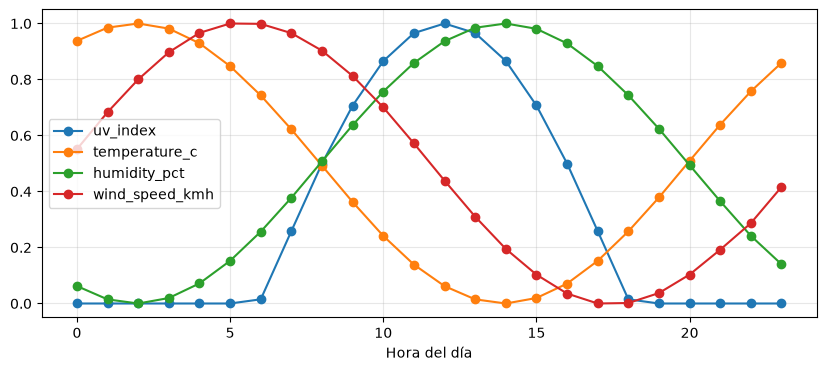

In [8]:
#Analizaremos los datos gráficamente
norm = (perfil - perfil.min()) / (perfil.max() - perfil.min())
norm[["uv_index", "temperature_c", "humidity_pct", "wind_speed_kmh"]].plot(marker="o", figsize=(10, 4))
plt.xlabel("Hora del día")
plt.grid(alpha=0.3)
plt.show()

Aquí podemos observar que hay un problema con los datos de temperatura, humedad relativa y velocidad del viento. Se muestran temperaturas máximas en la madrugada y mínimas al mediodía, así que va al revés, la humedad relativa debería ir a la par que la temperatura, cuanto más frío, mayor humedad relativa, por lo que también va al contario, en cuandto a la velocidad del viento, según los datos oficiales de Aruba las tardes suelen ser el momemento de máxima velocidad de viento, este dataset ahora mismo está mostrando lo contrario. 

Analizamos si el desfase es igual a lo largo del año

In [9]:
por_mes = df.groupby([df["timestamp"].dt.strftime("%Y-%m"),
                      df["timestamp"].dt.hour])["temperature_c"].mean()
por_mes.unstack().idxmax(axis=1)

timestamp
2025-09    2
2025-10    2
2025-11    2
2025-12    2
2026-01    2
2026-02    2
2026-03    2
2026-04    2
2026-05    2
2026-06    2
2026-07    2
2026-08    2
2026-09    2
dtype: int32

Las 2am es la hora de máxima temperatura a lo largo del año poer tanto el desfase es constante

In [10]:
COLUMNAS_DESFASADAS = ["temperature_c", "humidity_pct", "wind_speed_kmh"]

desplazadas = df[["station_id", "timestamp"] + COLUMNAS_DESFASADAS].copy() #Creamos una serie con las columnas afectadas
desplazadas["timestamp"] = desplazadas["timestamp"] + pd.Timedelta(hours=12) #Sumamos 12h a todas
desplazadas.head()

,station_id,timestamp,temperature_c,humidity_pct,wind_speed_kmh
0,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 12:00:00+00:00,32.4,68.9,23.1
1,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 12:05:00+00:00,32.4,68.9,23.1
2,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 12:10:00+00:00,32.6,68.7,23.0
3,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 12:15:00+00:00,32.6,68.6,23.0
4,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2025-09-01 12:20:00+00:00,32.8,68.6,22.8


In [11]:
#Unimos estas columnas con el resto del dataframe sustituyendo las antiguas 
df_corregido = (
    df.drop(columns=COLUMNAS_DESFASADAS)
      .merge(desplazadas, on=["station_id", "timestamp"], how="left")
)

In [12]:
df_corregido[COLUMNAS_DESFASADAS].isna().sum()

temperature_c     5184
humidity_pct      5184
wind_speed_kmh    5184
dtype: int64

Como hemos visto antes, había saltos entre tiempo, al haber desfasado las horas esos huecos las filas siguientes al hueco se quedan con nulos, por tanto, tocará borrarlas

In [13]:
df_corregido = df_corregido.dropna(subset=COLUMNAS_DESFASADAS) #Eliminamos nulos de esas columnas
df_corregido = df_corregido[df.columns].reset_index(drop=True)   # mismo orden de columnas
print("Nº filas antes: ",len(df), "Nº filas después: ", len(df_corregido))

Nº filas antes:  1292256 Nº filas después:  1287072


Volvemos a comprobar las máximas por hora

In [14]:
perfil_despues = df_corregido.groupby(df_corregido["timestamp"].dt.hour)[columnas].mean()
perfil_despues.idxmax()

temperature_c         14
humidity_pct           2
wind_speed_kmh        17
uv_index              12
pressure_hpa          22
wind_direction_deg    12
visibility_km         21
precipitation_mm      20
dtype: int32

Comprobamos gráficamente

Vemos que los resultados ya tienen sentido 

In [15]:
SALIDA_RUTA = Path("transformado/db_meteorologica_sinDesfase.csv.gz")

df_corregido.to_csv(SALIDA_RUTA, index=False, compression="gzip")